FINITE-SPEED PROPAGATION CHECK

   t  Support_Radius  Boundary_Speed
0.25        2.182247        2.909663
0.50        2.749459        1.832973
1.00        3.464102        1.154701
2.00        4.364495        0.727416
4.00        5.498919        0.458243

PASS: Support radius is finite for every tested positive time.
PASS: Support expands with time.
PASS: Boundary speed is finite for every tested positive time.


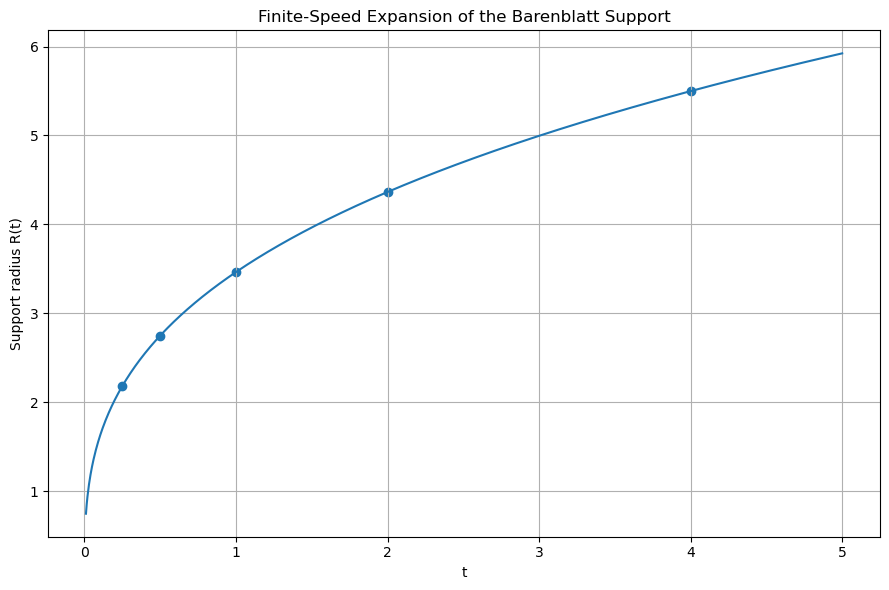

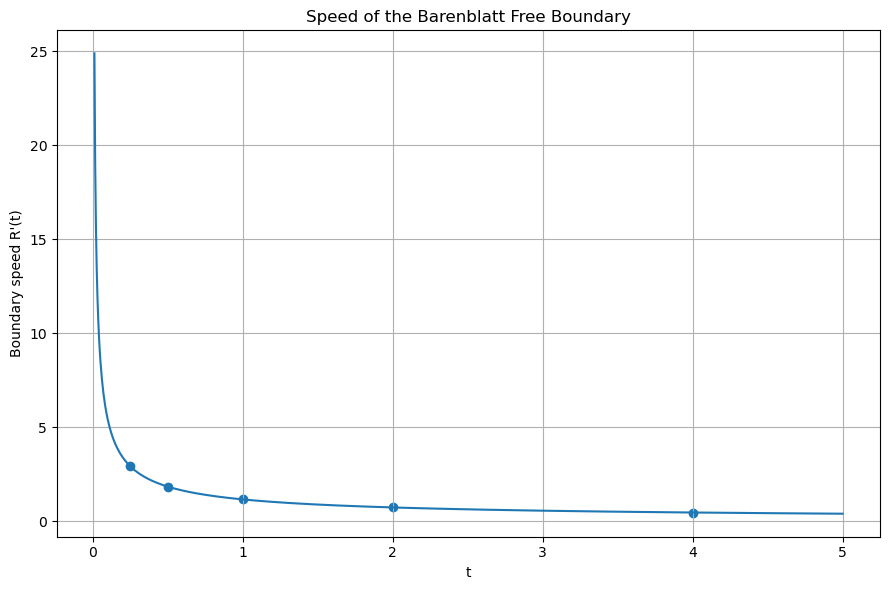

In [1]:
# ============================================================
# HOMEWORK 4.1 - PART IV
# FINITE-SPEED PROPAGATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PARAMETERS
# ============================================================

d = 1
m = 2.0
C = 1.0

beta = (
    1.0
    /
    (
        d * (m - 1.0)
        +
        2.0
    )
)

k = (
    (m - 1.0)
    /
    (2.0 * m)
    *
    beta
)


# ============================================================
# SUPPORT RADIUS
# ============================================================

def support_radius(t):

    return (
        np.sqrt(C / k)
        *
        t**beta
    )


# ============================================================
# FRONT SPEED
# ============================================================

def support_speed(t):

    return (
        np.sqrt(C / k)
        *
        beta
        *
        t**(beta - 1.0)
    )


# ============================================================
# TEST TIMES
# ============================================================

times = np.array([
    0.25,
    0.5,
    1.0,
    2.0,
    4.0
])


radii = support_radius(
    times
)

speeds = support_speed(
    times
)


results = pd.DataFrame({
    "t": times,
    "Support_Radius": radii,
    "Boundary_Speed": speeds
})


print("=" * 70)
print("FINITE-SPEED PROPAGATION CHECK")
print("=" * 70)

print()

print(
    results.to_string(
        index=False
    )
)


# ============================================================
# CHECKS
# ============================================================

assert np.all(
    np.isfinite(radii)
)

assert np.all(
    radii > 0
)

assert np.all(
    np.diff(radii) > 0
)

assert np.all(
    np.isfinite(speeds)
)

assert np.all(
    speeds > 0
)


print()

print(
    "PASS: Support radius is finite "
    "for every tested positive time."
)

print(
    "PASS: Support expands with time."
)

print(
    "PASS: Boundary speed is finite "
    "for every tested positive time."
)


# ============================================================
# PLOT SUPPORT RADIUS
# ============================================================

t_plot = np.linspace(
    0.01,
    5.0,
    1000
)


plt.figure(
    figsize=(9, 6)
)

plt.plot(
    t_plot,
    support_radius(t_plot)
)

plt.scatter(
    times,
    radii
)

plt.xlabel(
    "t"
)

plt.ylabel(
    "Support radius R(t)"
)

plt.title(
    "Finite-Speed Expansion of the Barenblatt Support"
)

plt.grid(
    True
)

plt.tight_layout()

plt.savefig(
    "hw41_part4_support_radius.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT BOUNDARY SPEED
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    t_plot,
    support_speed(t_plot)
)

plt.scatter(
    times,
    speeds
)

plt.xlabel(
    "t"
)

plt.ylabel(
    "Boundary speed R'(t)"
)

plt.title(
    "Speed of the Barenblatt Free Boundary"
)

plt.grid(
    True
)

plt.tight_layout()

plt.savefig(
    "hw41_part4_boundary_speed.png",
    dpi=300
)

plt.show()